# Data load & Sanity Check

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("processed_full")
DATA_DIR = OUTPUT_DIR / "normalized"

split = json.loads((OUTPUT_DIR / "split.json").read_text())

# Keep only songs with successfully generated windows
for part in ("train", "validation", "test"):
    original_count = len(split[part])

    split[part] = [
        song_id for song_id in split[part]
        if (DATA_DIR / str(song_id) / "windows.npz").is_file()
    ]

    print(f"{part}: {original_count} -> {len(split[part])}")

print("Total:", sum(len(split[p]) for p in ("train", "validation", "test")))

train: 1411 -> 1409
validation: 174 -> 174
test: 178 -> 178
Total: 1761


In [2]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# local setup
# device = torch.device(
#     "mps" if torch.backends.mps.is_available()
#     else "cuda" if torch.cuda.is_available()
#     else "cpu"
# )

# print("Device:", device)

# PACE - cuda expected
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Device:", device)

Device: cuda


### Model Pipeline

**One input window**  
↓  
**16 audio frames (16 × 80) + 15 previous note frames (15 × 7)**  
↓  
**CNN extracts features from the audio**  
↓  
**Audio features are combined with previous note information**  
↓  
**LSTM learns temporal/rhythmic patterns**  
↓  
**Predict 4 timesteps (4 × 7 classes)**

In [3]:
class TaikoNationBaseline(nn.Module):
    def __init__(self):
        super().__init__()

        # Split the 1385 inputs; split them back into audio and notes
        self.conv1 = nn.Conv1d(80, 16, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool1d(2)

        self.conv2 = nn.Conv1d(16, 32, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool1d(2)

        self.audio_fc = nn.Linear(32 * 4, 128)

        self.lstm1 = nn.LSTM(
            input_size=8,
            hidden_size=64,
            batch_first=True
        )

        self.lstm2 = nn.LSTM(
            input_size=64,
            hidden_size=64,
            batch_first=True
        )

        self.output = nn.Linear(64, 28)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.8)

    # send the audio through the CNN to find useful patters in the audio features
    def forward(self, x):
        audio = x[:, :1280].reshape(-1, 16, 80)
        notes = x[:, 1280:].reshape(-1, 15, 7)

        audio = audio.transpose(1, 2)

        audio = self.relu(self.conv1(audio))
        audio = self.dropout(audio)
        audio = self.pool1(audio)

        audio = self.relu(self.conv2(audio))
        audio = self.pool2(audio)

        audio = audio.flatten(1)
        audio = self.relu(self.audio_fc(audio))
        audio = audio.reshape(-1, 16, 8)

        note_bias = torch.ones(
            notes.shape[0], 15, 1,
            device=notes.device,
            dtype=notes.dtype
        )

        note_history = torch.cat([notes, note_bias], dim=2)

        current_placeholder = torch.ones(
            notes.shape[0], 1, 8,
            device=notes.device,
            dtype=notes.dtype
        )

        note_context = torch.cat(
            [note_history, current_placeholder],
            dim=1
        )

        # Combine audio and previous-note information
        combined = audio * note_context

        combined, _ = self.lstm1(combined)
        combined = self.relu(combined)
        combined = self.dropout(combined)

        # LSTM learns the temporal pattern
        combined, _ = self.lstm2(combined)
        combined = self.relu(combined)
        combined = self.dropout(combined)

        final = combined[:, -1, :]
        logits = self.output(final)

        return logits.reshape(-1, 4, 7)

# sanity check

In [4]:
model = TaikoNationBaseline().to(device)
with np.load(DATA_DIR / str(split["train"][0]) / "windows.npz") as data:
    sample = torch.from_numpy(data["X"][:8].astype(np.float32)).to(device)
with torch.no_grad():
    output = model(sample)
print("Input:", sample.shape, "Output:", output.shape)
assert output.shape == (sample.shape[0], 4, 7)

Input: torch.Size([8, 1385]) Output: torch.Size([8, 4, 7])


# data loader

Modified because we need to handle ~2k data.

In [5]:
# Load one chart at a time rather than concatenating all windows into RAM.
# Group batches by song to avoid repeatedly opening large NPZ files.
from torch.utils.data import Dataset, DataLoader, Sampler
import bisect

class SongWindowDataset(Dataset):
    def __init__(self, song_ids):
        self.song_ids = [str(x) for x in song_ids]
        self.lengths = []
        for song_id in self.song_ids:
            with np.load(DATA_DIR / song_id / "windows.npz") as d:
                self.lengths.append(len(d["X"]))
        self.ends = np.cumsum(self.lengths).tolist()
        self._cached_song = None
        self._cached_arrays = None

    def __len__(self):
        return self.ends[-1] if self.ends else 0

    def __getitem__(self, index):
        song_index = bisect.bisect_right(self.ends, index)
        local_index = index - (self.ends[song_index - 1] if song_index else 0)
        if self._cached_song != song_index:
            path = DATA_DIR / self.song_ids[song_index] / "windows.npz"
            with np.load(path) as d:
                self._cached_arrays = (d["X"].astype(np.float32),
                                       d["Y"].astype(np.float32))
            self._cached_song = song_index
        X, Y = self._cached_arrays
        return torch.from_numpy(X[local_index]), torch.from_numpy(Y[local_index])

class SongBatchSampler(Sampler):
    def __init__(self, dataset, batch_size, shuffle=False):
        self.dataset, self.batch_size, self.shuffle = dataset, batch_size, shuffle

    def __iter__(self):
        song_order = np.arange(len(self.dataset.lengths))
        if self.shuffle:
            np.random.shuffle(song_order)
        for s in song_order:
            start = self.dataset.ends[s-1] if s else 0
            indices = np.arange(start, self.dataset.ends[s])
            if self.shuffle:
                np.random.shuffle(indices)
            for offset in range(0, len(indices), self.batch_size):
                yield indices[offset:offset+self.batch_size].tolist()

    def __len__(self):
        return sum((n + self.batch_size - 1)//self.batch_size
                   for n in self.dataset.lengths)

train_dataset = SongWindowDataset(split["train"])
val_dataset = SongWindowDataset(split["validation"])

BATCH_SIZE = 128

train_loader = DataLoader(train_dataset,
    batch_sampler=SongBatchSampler(train_dataset, BATCH_SIZE, shuffle=True), num_workers=0)
val_loader = DataLoader(val_dataset,
    batch_sampler=SongBatchSampler(val_dataset, BATCH_SIZE, 16), num_workers=0)
print("Train windows:", len(train_dataset), "Val windows:", len(val_dataset))
print("Train batches:", len(train_loader), "Val batches:", len(val_loader))

Train windows: 6862438 Val windows: 843300
Train batches: 54312 Val batches: 6672


# loss + optimizer

In [6]:
# measures how wrong the model's predictions are compared withthe correct note classes
criterion = nn.CrossEntropyLoss()

# changes the model's weights to reduce the loss; Adam is a popular optimizer that works well in many situations
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-5
)

# training & validation functions

In [7]:
# predict -> calculate loss -> backpropagate -> update weights
def train_epoch(model, loader):
    model.train()

    total_loss = 0.0

    for X, Y in loader:
        X = X.to(device)
        Y = Y.to(device)

        # before processing the new batch, we clear the gradients from the previous batch.
        optimizer.zero_grad()

        logits = model(X)
        targets = Y.argmax(dim=2)

        loss = criterion(
            logits.reshape(-1, 7),
            targets.reshape(-1)
        )

        # learn from loss; how did each model weight contribute to the loss? how should we change the weights to reduce the loss?
        loss.backward()
        # use gradients to update the model's weights  
        optimizer.step()

        total_loss += loss.item()

    # returns the average loss across all batches in the epoch
    return total_loss / len(loader)


def evaluate(model, loader):
    model.eval()

    total_loss = 0.0

    with torch.no_grad():
        for X, Y in loader:
            X = X.to(device)
            Y = Y.to(device)

            logits = model(X)
            targets = Y.argmax(dim=2)

            loss = criterion(
                logits.reshape(-1, 7),
                targets.reshape(-1)
            )

            total_loss += loss.item()

    return total_loss / len(loader)

# Train 10 epochs

In [8]:
# first 10 epochs

import time
start_time = time.time()

train_losses = []
val_losses = []

for epoch in range(10):
    train_loss = train_epoch(model, train_loader)
    val_loss = evaluate(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
        f"Elapsed time: {(time.time() - start_time) / 60:.1f} min"
    )

Epoch 01 | Train Loss: 0.6181 | Val Loss: 0.4414Elapsed time: 4.2 min
Epoch 02 | Train Loss: 0.4776 | Val Loss: 0.4320Elapsed time: 8.3 min
Epoch 03 | Train Loss: 0.4606 | Val Loss: 0.4252Elapsed time: 12.5 min
Epoch 04 | Train Loss: 0.4506 | Val Loss: 0.4198Elapsed time: 16.6 min
Epoch 05 | Train Loss: 0.4434 | Val Loss: 0.4162Elapsed time: 20.8 min
Epoch 06 | Train Loss: 0.4389 | Val Loss: 0.4152Elapsed time: 25.0 min
Epoch 07 | Train Loss: 0.4361 | Val Loss: 0.4122Elapsed time: 29.1 min
Epoch 08 | Train Loss: 0.4340 | Val Loss: 0.4104Elapsed time: 33.2 min
Epoch 09 | Train Loss: 0.4323 | Val Loss: 0.4098Elapsed time: 37.4 min
Epoch 10 | Train Loss: 0.4305 | Val Loss: 0.4072Elapsed time: 41.5 min


# Second stage - fine tuning

Replicate paper's training procedure with batch size 1 and learning rate 5e-6

In [10]:
train_loader_finetune = DataLoader(
    train_dataset,
    batch_sampler=SongBatchSampler(train_dataset, 128, shuffle=True),
    num_workers=0
)

optimizer = torch.optim.Adam(model.parameters(), lr=5e-6)

for epoch in range(2):
    train_loss = train_epoch(model, train_loader_finetune)
    val_loss = evaluate(model, val_loader)
    print(
        f"Fine-tune Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}"
    )

Fine-tune Epoch 01 | Train Loss: 0.4305 | Val Loss: 0.4047
Fine-tune Epoch 02 | Train Loss: 0.4280 | Val Loss: 0.4037


# save model

In [11]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "train_losses": train_losses,
        "val_losses": val_losses,
        "split": split
    },
    # "taikonation_smoke_test.pt"
    "taikonation_full.pt"
)

print("Saved.")

Saved.


# Make predictions on the test song

### Test Prediction Pipeline

**Trained Model + Test Audio/Note Windows**  
↓  
**Model Prediction**  
↓  
**Raw Scores (Logits)**  
↓  
**Softmax**  
↓  
**Probabilities for Each of the 7 Note Classes**  
↓  
**Used for Chart Generation**

In [12]:
# Inference is now performed song-by-song in Cell 31, in small GPU batches.
model.eval()
INFERENCE_BATCH_SIZE = 64
print("Ready to evaluate", len(split["test"]), "test charts")

Ready to evaluate 178 test charts


# Combining the overlapping predictions from different windows to produce one final 7-class probability distribution for each 23 ms timestep.

In [13]:
def aggregate_overlapping_predictions(probs):
    # probs: (number_of_windows, 4, 7), from ONE song only
    n = len(probs)
    if n == 0:
        return np.empty((0, 7), dtype=np.float32)
    aggregated = np.zeros((n + 3, 7), dtype=np.float32)
    counts = np.zeros(n + 3, dtype=np.float32)
    for j in range(4):
        aggregated[j:j+n] += probs[:, j, :]
        counts[j:j+n] += 1
    return aggregated / counts[:, None]

# Generating chart

Takes the final probability distribution for every 23 ms timestep and turns it into an actual generated chart.

In [14]:
CLASS_NAMES = ["none", "don", "ka", "DON", "KA", "drumroll", "denden"]
rng = np.random.default_rng(42)

def sample_chart(aggregated):
    return np.array([rng.choice(7, p=p / p.sum()) for p in aggregated],
                    dtype=np.int64)

# Target vs. Model generated

In [15]:
def reconstruct_true_sequence(Y):
    # Y: (number_of_windows, 4, 7), for ONE song only
    targets = Y.argmax(axis=2)
    n = len(targets)
    if n == 0:
        return np.empty(0, dtype=np.int64)
    sequence = np.empty(n + 3, dtype=np.int64)
    sequence[:n] = targets[:, 0]
    sequence[n:] = targets[-1, 1:4]
    return sequence

# Onset evaluation

Regardless of note type like Don and Ka, this measures generated notes occur near the ground-truth note timings (within +- 23ms).

In [16]:
def onset_metrics(true_seq, pred_seq, tolerance=1):
    true_onsets = np.where(true_seq != 0)[0]
    pred_onsets = np.where(pred_seq != 0)[0]

    matched_true = set()
    matches = 0

    for pred in pred_onsets:
        candidates = [
            t for t in true_onsets
            if abs(t - pred) <= tolerance and t not in matched_true
        ]

        if candidates:
            best = min(candidates, key=lambda t: abs(t - pred))
            matched_true.add(best)
            matches += 1

    precision = matches / len(pred_onsets) if len(pred_onsets) else 0
    recall = matches / len(true_onsets) if len(true_onsets) else 0

    if precision + recall:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0

    return precision, recall, f1, matches

# Onset + type eval

In [17]:
def joint_onset_type_metrics(true_seq, pred_seq, tolerance=1):
    true_onsets = np.where(true_seq != 0)[0]
    pred_onsets = np.where(pred_seq != 0)[0]

    matched_true = set()
    matches = 0

    for pred in pred_onsets:
        candidates = [
            t for t in true_onsets
            if abs(t - pred) <= tolerance
            and true_seq[t] == pred_seq[pred]
            and t not in matched_true
        ]

        if candidates:
            best = min(candidates, key=lambda t: abs(t - pred))
            matched_true.add(best)
            matches += 1

    precision = matches / len(pred_onsets) if len(pred_onsets) else 0
    recall = matches / len(true_onsets) if len(true_onsets) else 0

    if precision + recall:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0

    return precision, recall, f1, matches

def score_from_counts(tp, predicted, actual):
    precision = tp / predicted if predicted else 0.0
    recall = tp / actual if actual else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1

# Micro-averaged evaluation: accumulate counts across songs, never across boundaries.
model.eval()
total_true = total_pred = total_onset_matches = total_joint_matches = 0
true_class_counts = np.zeros(7, dtype=np.int64)
pred_class_counts = np.zeros(7, dtype=np.int64)

for song_index, song_id in enumerate(split["test"], start=1):
    with np.load(DATA_DIR / str(song_id) / "windows.npz") as data:
        X = data["X"]
        Y = data["Y"]
        if len(X) == 0:
            continue
        song_probs = []
        with torch.no_grad():
            for start in range(0, len(X), INFERENCE_BATCH_SIZE):
                batch = torch.from_numpy(
                    X[start:start + INFERENCE_BATCH_SIZE].astype(np.float32)
                ).to(device)
                logits = model(batch)
                song_probs.append(torch.softmax(logits, dim=2).cpu().numpy())
        probs = np.concatenate(song_probs, axis=0)
        generated = sample_chart(aggregate_overlapping_predictions(probs))
        true_sequence = reconstruct_true_sequence(Y)
        assert len(generated) == len(true_sequence)

        _, _, _, onset_matches = onset_metrics(true_sequence, generated, tolerance=1)
        _, _, _, joint_matches = joint_onset_type_metrics(true_sequence, generated, tolerance=1)
        total_onset_matches += onset_matches
        total_joint_matches += joint_matches
        total_true += np.count_nonzero(true_sequence)
        total_pred += np.count_nonzero(generated)
        true_class_counts += np.bincount(true_sequence, minlength=7)
        pred_class_counts += np.bincount(generated, minlength=7)
    if song_index % 20 == 0:
        print(f"Evaluated {song_index}/{len(split['test'])} charts")

precision, recall, f1 = score_from_counts(total_onset_matches, total_pred, total_true)
precision_type, recall_type, f1_type = score_from_counts(total_joint_matches, total_pred, total_true)
print(f"Onset: precision={precision:.4f}, recall={recall:.4f}, F1={f1:.4f}")
print(f"Onset + type: precision={precision_type:.4f}, recall={recall_type:.4f}, F1={f1_type:.4f}")
for name, actual, predicted in zip(CLASS_NAMES, true_class_counts, pred_class_counts):
    print(f"{name:10s} true={actual:8d} generated={predicted:8d}")

Evaluated 20/178 charts
Evaluated 40/178 charts
Evaluated 60/178 charts
Evaluated 80/178 charts
Evaluated 100/178 charts
Evaluated 120/178 charts
Evaluated 140/178 charts
Evaluated 160/178 charts
Onset: precision=0.5554, recall=0.5354, F1=0.5452
Onset + type: precision=0.4403, recall=0.4244, F1=0.4322
none       true=  749586 generated=  754610
don        true=   48914 generated=   47430
ka         true=   39007 generated=   37175
DON        true=    2698 generated=    2059
KA         true=    1356 generated=     542
drumroll   true=   31052 generated=   30900
denden     true=   16397 generated=   16294


In [18]:
results = {
    "onset_precision": float(precision),
    "onset_recall": float(recall),
    "onset_f1": float(f1),
    "joint_precision": float(precision_type),
    "joint_recall": float(recall_type),
    "joint_f1": float(f1_type)
}

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "results": results,
        "split": split
    },
    "taikonation_full.pt"
)

print("Model and evaluation results saved.")
print(results)

Model and evaluation results saved.
{'onset_precision': 0.5554166666666667, 'onset_recall': 0.5354028000918063, 'onset_f1': 0.5452261306532663, 'joint_precision': 0.4402827380952381, 'joint_recall': 0.42441760385586413, 'joint_f1': 0.43220462779011337}


# OCHuman-style Evaluation (±1 timestep)

In [19]:
# Uses the already-trained model

import numpy as np
import torch

def ochuman_score(true_seq, pred_seq, tolerance=1):
    true_onsets = np.flatnonzero(true_seq != 0)
    pred_mask = pred_seq != 0

    if len(true_onsets) == 0:
        return 0, 0

    matched = 0
    for t in true_onsets:
        left = max(0, t - tolerance)
        right = min(len(pred_seq), t + tolerance + 1)

        if np.any(pred_mask[left:right]):
            matched += 1

    return matched, len(true_onsets)


model.eval()

total_matched = 0
total_true = 0
song_scores = []

for song_index, song_id in enumerate(split["test"], start=1):

    with np.load(DATA_DIR / str(song_id) / "windows.npz") as data:
        X = data["X"]
        Y = data["Y"]

        if len(X) == 0:
            continue

        song_probs = []

        with torch.no_grad():
            for start in range(0, len(X), INFERENCE_BATCH_SIZE):
                batch = torch.from_numpy(
                    X[start:start + INFERENCE_BATCH_SIZE].astype(np.float32)
                ).to(device)

                logits = model(batch)
                probs = torch.softmax(logits, dim=2)
                song_probs.append(probs.cpu().numpy())

        probs = np.concatenate(song_probs, axis=0)

        generated = sample_chart(
            aggregate_overlapping_predictions(probs)
        )
        true_sequence = reconstruct_true_sequence(Y)

        assert len(generated) == len(true_sequence)

        matched, actual = ochuman_score(
            true_sequence,
            generated,
            tolerance=1
        )

        total_matched += matched
        total_true += actual

        if actual > 0:
            song_scores.append(matched / actual)

    if song_index % 20 == 0:
        print(f"Evaluated {song_index}/{len(split['test'])} charts")


# Overall score (micro-average)
ochuman_micro = total_matched / total_true if total_true else 0

# Per-chart average (macro-average)
ochuman_macro = np.mean(song_scores) if song_scores else 0

print("\n===== OCHuman-style Results =====")
print(f"Micro-average: {ochuman_micro:.4f} ({ochuman_micro:.2%})")
print(f"Macro-average: {ochuman_macro:.4f} ({ochuman_macro:.2%})")
print(f"Charts evaluated: {len(song_scores)}")

# Save results separately
np.savez(
    "ochuman_results.npz",
    micro=ochuman_micro,
    macro=ochuman_macro,
    song_scores=np.array(song_scores)
)

print("Results saved to ochuman_results.npz")

Evaluated 20/178 charts
Evaluated 40/178 charts
Evaluated 60/178 charts
Evaluated 80/178 charts
Evaluated 100/178 charts
Evaluated 120/178 charts
Evaluated 140/178 charts
Evaluated 160/178 charts

===== OCHuman-style Results =====
Micro-average: 0.5552 (55.52%)
Macro-average: 0.5375 (53.75%)
Charts evaluated: 178
Results saved to ochuman_results.npz


Text(0.5, 0, 'Timestep (1 step = 23ms)')

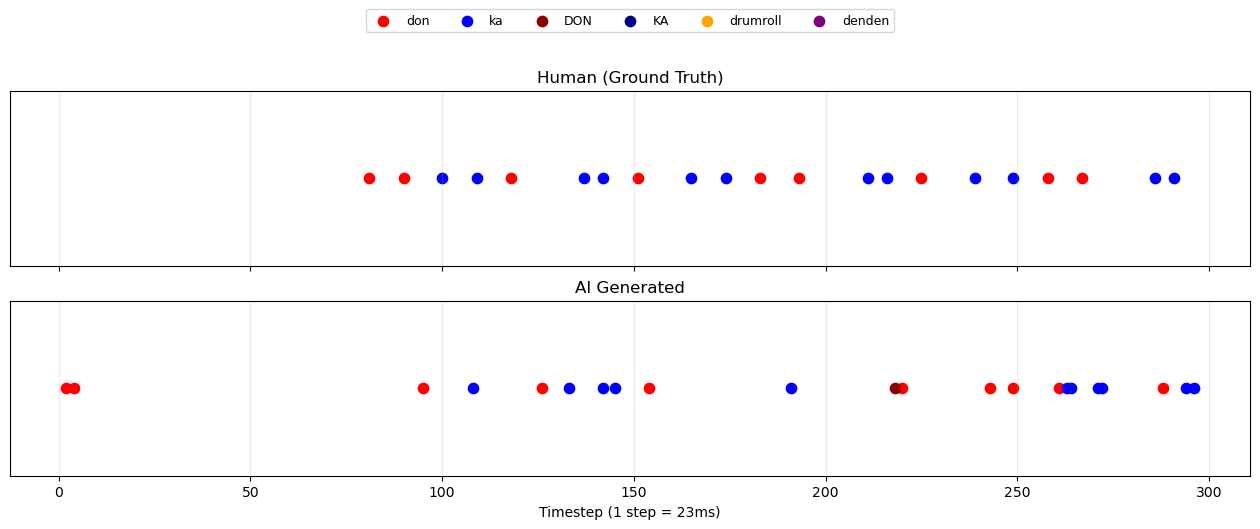

In [21]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Select a test song
song_id = split["test"][0]

with np.load(DATA_DIR / str(song_id) / "windows.npz") as data:
    X = data["X"]
    Y = data["Y"]

# Generate predictions
model.eval()
song_probs = []

with torch.no_grad():
    for start in range(0, len(X), INFERENCE_BATCH_SIZE):
        batch = torch.from_numpy(
            X[start:start + INFERENCE_BATCH_SIZE].astype(np.float32)
        ).to(device)

        logits = model(batch)
        song_probs.append(
            torch.softmax(logits, dim=2).cpu().numpy()
        )

probs = np.concatenate(song_probs, axis=0)

generated = sample_chart(
    aggregate_overlapping_predictions(probs)
)
true_sequence = reconstruct_true_sequence(Y)

assert len(generated) == len(true_sequence)

# Plot the first 300 timesteps (~6.9 seconds if 23ms per step)
start_step = 0
num_steps = 300
end_step = min(start_step + num_steps, len(true_sequence))

colors = {
    1: "red",       # don
    2: "blue",      # ka
    3: "darkred",   # DON
    4: "darkblue",  # KA
    5: "orange",    # drumroll
    6: "purple"     # denden
}

fig, axes = plt.subplots(2, 1, figsize=(16, 5), sharex=True)

for ax, seq, title in zip(
    axes,
    [true_sequence, generated],
    ["Human (Ground Truth)", "AI Generated"]
):
    for note_type, color in colors.items():
        positions = np.where(
            seq[start_step:end_step] == note_type
        )[0] + start_step

        ax.scatter(
            positions,
            np.full(len(positions), 1),
            color=color,
            s=55,
            label=CLASS_NAMES[note_type]
        )

    ax.set_title(title)
    ax.set_ylim(0.5, 1.5)
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.25)

axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.5),
    ncol=6,
    fontsize=9
)

axes[-1].set_xlabel("Timestep (1 step = 23ms)")

# autoregressive generation

===== Autoregressive Results =====
Song: 0013_Favorite Days
Onset Precision: 0.4124
Onset Recall:    0.2312
Onset F1:        0.2962
Joint F1:        0.1157
True notes: 1008
Generated notes: 565


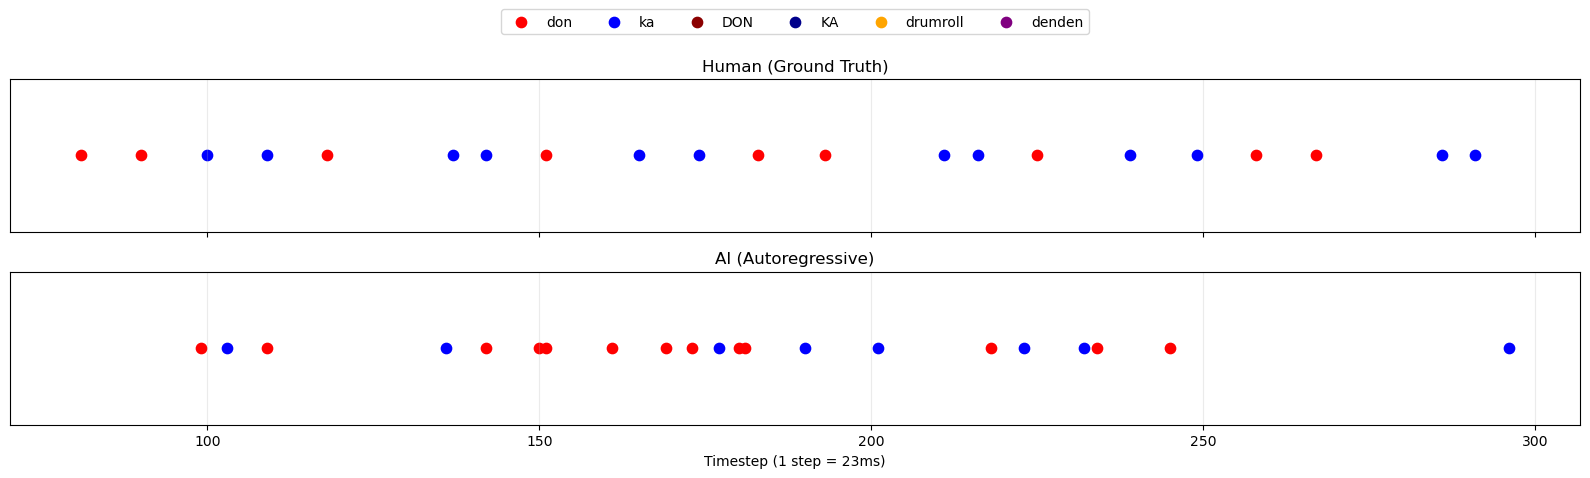

In [22]:
import numpy as np
import torch
import matplotlib.pyplot as plt

def generate_autoregressive(model, X, device, seed=42):
    """
    Autoregressive Taiko chart generation.

    X: preprocessed windows, shape (N, 1385)
    Only X[:, :1280] (audio) is used.
    Ground-truth note history is NEVER used.
    """
    model.eval()
    rng = np.random.default_rng(seed)

    n = len(X)
    total_steps = n + 3

    generated = np.zeros(total_steps, dtype=np.int64)

    # Accumulate overlapping predictions
    prob_sums = np.zeros((total_steps, 7), dtype=np.float32)
    counts = np.zeros(total_steps, dtype=np.int32)

    eye = np.eye(7, dtype=np.float32)

    # Keep only audio; discard ground-truth note history
    audio = X[:, :1280].astype(np.float32)

    with torch.inference_mode():
        for t in range(total_steps):

            if t < n:
                # Previous 15 GENERATED notes
                history = np.zeros((15, 7), dtype=np.float32)

                start = max(0, t - 15)
                previous = generated[start:t]

                if len(previous) > 0:
                    history[-len(previous):] = eye[previous]

                # Construct model input
                x = np.concatenate([
                    audio[t],
                    history.reshape(-1)
                ])

                batch = torch.from_numpy(
                    x[None, :]
                ).to(device)

                logits = model(batch)

                probs = torch.softmax(
                    logits, dim=2
                )[0].cpu().numpy()

                # Predictions for t, t+1, t+2, t+3
                for j in range(4):
                    idx = t + j
                    prob_sums[idx] += probs[j]
                    counts[idx] += 1

            # Sample current timestep using predictions
            # available so far (no future-note leakage)
            if counts[t] > 0:
                p = prob_sums[t] / counts[t]
                p = p / p.sum()
                generated[t] = rng.choice(7, p=p)

    return generated


# ========================================
# Evaluate one test song
# ========================================

song_id = split["test"][0]

with np.load(
    DATA_DIR / str(song_id) / "windows.npz"
) as data:
    X = data["X"]
    Y = data["Y"]

true_sequence = reconstruct_true_sequence(Y)

generated_ar = generate_autoregressive(
    model, X, device, seed=42
)

assert len(generated_ar) == len(true_sequence)

# Calculate metrics
p, r, f1, _ = onset_metrics(
    true_sequence,
    generated_ar,
    tolerance=1
)

jp, jr, jf1, _ = joint_onset_type_metrics(
    true_sequence,
    generated_ar,
    tolerance=1
)

print("===== Autoregressive Results =====")
print("Song:", song_id)
print(f"Onset Precision: {p:.4f}")
print(f"Onset Recall:    {r:.4f}")
print(f"Onset F1:        {f1:.4f}")
print(f"Joint F1:        {jf1:.4f}")

print("True notes:", np.count_nonzero(true_sequence))
print("Generated notes:", np.count_nonzero(generated_ar))

# ========================================
# Visualize first 300 timesteps
# ========================================

start_step = 0
end_step = min(300, len(true_sequence))

colors = {
    1: "red",
    2: "blue",
    3: "darkred",
    4: "darkblue",
    5: "orange",
    6: "purple"
}

fig, axes = plt.subplots(
    2, 1, figsize=(16, 5), sharex=True
)

for ax, seq, title in zip(
    axes,
    [true_sequence, generated_ar],
    ["Human (Ground Truth)", "AI (Autoregressive)"]
):
    for note_type, color in colors.items():
        positions = np.where(
            seq[start_step:end_step] == note_type
        )[0] + start_step

        ax.scatter(
            positions,
            np.ones(len(positions)),
            color=color,
            s=55,
            label=CLASS_NAMES[note_type]
        )

    ax.set_title(title)
    ax.set_ylim(0.5, 1.5)
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.25)

axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.5),
    ncol=6
)

axes[-1].set_xlabel("Timestep (1 step = 23ms)")

plt.tight_layout()
plt.savefig(
    "human_vs_autoregressive.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [33]:

import numpy as np
import pandas as pd
import torch
import json
import time
from pathlib import Path

# ==========================================
# 1. Configuration
# ==========================================

SAVE_DIR = Path("ar_test_178")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

test_songs = split["test"]

# ==========================================
# 2. Helper functions
# ==========================================

def remove_adjacent_notes(sequence):
    cleaned = sequence.copy()

    for t in range(1, len(sequence)):
        if sequence[t - 1] != 0 and sequence[t] != 0:
            cleaned[t] = 0

    return cleaned


def to_binary_chart(sequence):
    sequence = np.asarray(sequence)

    # Discrete notes
    binary = np.isin(sequence, [1, 2, 3, 4])

    # Drumroll / Denden: only count onset
    held = np.isin(sequence, [5, 6])
    starts = np.r_[True, sequence[1:] != sequence[:-1]]

    binary |= held & starts
    return binary.astype(np.uint8)


def paper_ochuman(human, ai):
    """
    Paper-style approximation:
    Exact binary agreement, with ±1 timestep
    tolerance for human note onsets.
    """
    human = np.asarray(human, dtype=bool)
    ai = np.asarray(ai, dtype=bool)

    assert len(human) == len(ai)

    correct = (human == ai)

    nearby = ai.copy()
    nearby[1:] |= ai[:-1]
    nearby[:-1] |= ai[1:]

    correct |= human & nearby

    return float(correct.mean())


def extract_patterns(binary_chart, window=8):
    chart = np.asarray(binary_chart, dtype=np.uint8)

    return {
        tuple(chart[i:i + window])
        for i in range(len(chart) - window + 1)
    }


def calculate_paper_metrics(human, generated):
    h = to_binary_chart(human)
    a = to_binary_chart(generated)

    dc = float(np.mean(h == a) * 100)
    oc = paper_ochuman(h, a) * 100

    hp = extract_patterns(h)
    ap = extract_patterns(a)

    over = len(ap) / 256 * 100
    hi = len(hp & ap) / len(hp) * 100 if hp else 0.0

    return {
        "DCHuman": dc,
        "OCHuman": oc,
        "Over_PSpace": over,
        "HI_PSpace": hi,
        "human_onsets": int(h.sum()),
        "ai_onsets": int(a.sum())
    }


def calculate_f1_metrics(human, predicted):
    p, r, f1, onset_matches = onset_metrics(
        human, predicted, tolerance=1
    )

    jp, jr, jf1, joint_matches = joint_onset_type_metrics(
        human, predicted, tolerance=1
    )

    return {
        "onset_precision": float(p),
        "onset_recall": float(r),
        "onset_f1": float(f1),
        "joint_precision": float(jp),
        "joint_recall": float(jr),
        "joint_f1": float(jf1),
        "onset_matches": int(onset_matches),
        "joint_matches": int(joint_matches)
    }


# ==========================================
# 3. Evaluate 178 test songs
# ==========================================

model.eval()

all_results = []
start_time = time.time()

for song_index, song_id in enumerate(test_songs, start=1):

    save_path = SAVE_DIR / f"{song_id}.npz"

    # Resume from previously saved sequences
    if save_path.exists():
        with np.load(save_path) as data:
            true_seq = data["human"]
            generated = data["generated"]
            generated_clean = data["clean"]
    else:
        with np.load(
            DATA_DIR / str(song_id) / "windows.npz"
        ) as data:
            X = data["X"]
            Y = data["Y"]

        if len(X) == 0:
            continue

        true_seq = reconstruct_true_sequence(Y)

        # Same seed as original evaluation
        generated = generate_autoregressive(
            model, X, device, seed=42 + song_index
        )

        assert len(generated) == len(true_seq)

        generated_clean = remove_adjacent_notes(generated)

        # Save all sequences immediately
        np.savez_compressed(
            save_path,
            human=true_seq,
            generated=generated,
            clean=generated_clean
        )

    # Calculate both types of metrics
    result = {"song_id": str(song_id)}

    for label, predicted in [
        ("raw", generated),
        ("clean", generated_clean)
    ]:
        result[label] = {
            **calculate_f1_metrics(true_seq, predicted),
            **calculate_paper_metrics(true_seq, predicted)
        }

    all_results.append(result)

    # Save progress after every song
    with open(SAVE_DIR / "results.json", "w") as f:
        json.dump(all_results, f, indent=2)

    if song_index % 10 == 0 or song_index == len(test_songs):
        elapsed = (time.time() - start_time) / 60

        print(
            f"Evaluated {song_index}/{len(test_songs)} "
            f"| Elapsed: {elapsed:.1f} min",
            flush=True
        )


# ==========================================
# 4. Aggregate results
# ==========================================

print("\n========== FINAL TEST RESULTS ==========")
print(f"Songs evaluated: {len(all_results)}")

summary = []

for label in ["raw", "clean"]:
    print(f"\n========== {label.upper()} ==========")

    metrics = [
        "onset_precision",
        "onset_recall",
        "onset_f1",
        "joint_precision",
        "joint_recall",
        "joint_f1",
        "DCHuman",
        "OCHuman",
        "Over_PSpace",
        "HI_PSpace"
    ]

    for metric in metrics:
        values = [r[label][metric] for r in all_results]
        mean = float(np.mean(values))

        if metric in ["DCHuman", "OCHuman",
                      "Over_PSpace", "HI_PSpace"]:
            print(f"{metric:20s}: {mean:.3f}%")
        else:
            print(f"{metric:20s}: {mean:.4f}")

        summary.append({
            "version": label,
            "metric": metric,
            "mean": mean
        })

pd.DataFrame(summary).to_csv(
    SAVE_DIR / "summary.csv", index=False
)

print(
    f"\nTotal time: {(time.time()-start_time)/60:.2f} min"
)
print(f"All sequences saved in: {SAVE_DIR.resolve()}")


/tmp/ipykernel_1017200/953919695.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


Evaluated 10/178 | Elapsed: 0.7 min
Evaluated 20/178 | Elapsed: 1.4 min
Evaluated 30/178 | Elapsed: 2.1 min
Evaluated 40/178 | Elapsed: 2.7 min
Evaluated 50/178 | Elapsed: 3.4 min
Evaluated 60/178 | Elapsed: 4.3 min
Evaluated 70/178 | Elapsed: 5.1 min
Evaluated 80/178 | Elapsed: 5.9 min
Evaluated 90/178 | Elapsed: 6.6 min
Evaluated 100/178 | Elapsed: 7.4 min
Evaluated 110/178 | Elapsed: 8.1 min
Evaluated 120/178 | Elapsed: 8.8 min
Evaluated 130/178 | Elapsed: 9.4 min
Evaluated 140/178 | Elapsed: 9.9 min
Evaluated 150/178 | Elapsed: 10.5 min
Evaluated 160/178 | Elapsed: 11.3 min
Evaluated 170/178 | Elapsed: 12.0 min
Evaluated 178/178 | Elapsed: 12.7 min

========== FINAL TEST RESULTS ==========
Songs evaluated: 178

========== RAW ==========
onset_precision     : 0.3122
onset_recall        : 0.2845
onset_f1            : 0.2898
joint_precision     : 0.1125
joint_recall        : 0.1030
joint_f1            : 0.1047
DCHuman             : 81.879%
OCHuman             : 83.843%
Over_PSpace    

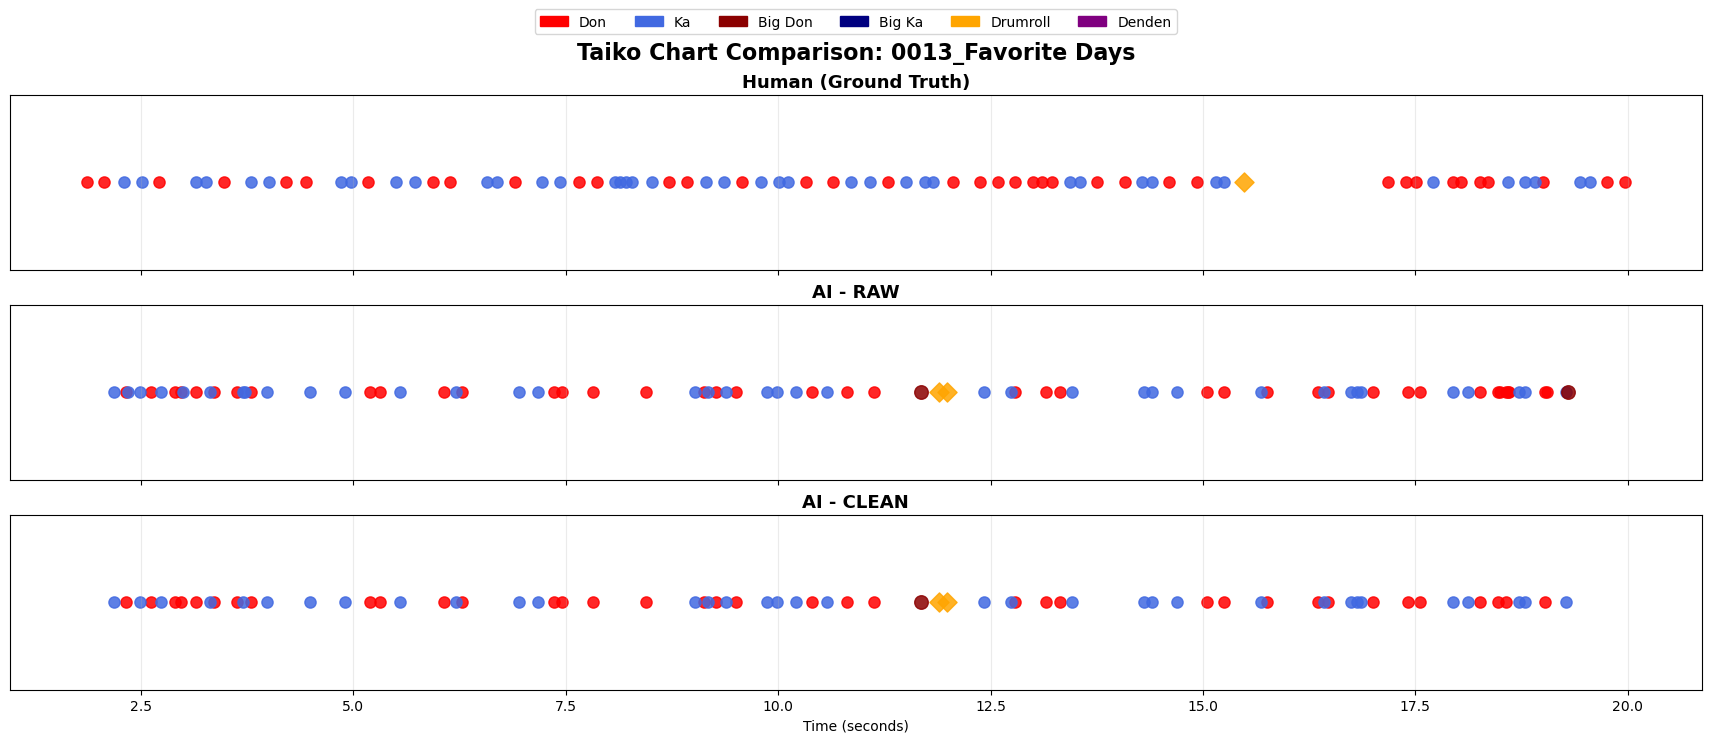

Song: 0013_Favorite Days
Displayed: 0-20 seconds
Saved: taiko_chart_comparison.png


In [34]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Patch

SAVE_DIR = Path("ar_test_178")

# First test song
song_id = str(split["test"][0])

with np.load(SAVE_DIR / f"{song_id}.npz") as data:
    human = data["human"]
    raw = data["generated"]
    clean = data["clean"]

# Display first 20 seconds
STEP_SECONDS = 0.023
START_SEC = 0
END_SEC = 20

start = int(START_SEC / STEP_SECONDS)
end = min(int(END_SEC / STEP_SECONDS), len(human))

NOTE_NAMES = {
    1: "Don",
    2: "Ka",
    3: "Big Don",
    4: "Big Ka",
    5: "Drumroll",
    6: "Denden"
}

NOTE_COLORS = {
    1: "red",
    2: "royalblue",
    3: "darkred",
    4: "navy",
    5: "orange",
    6: "purple"
}

fig, axes = plt.subplots(
    3, 1,
    figsize=(17, 7),
    sharex=True,
    constrained_layout=True
)

for ax, (label, seq) in zip(axes, [
    ("Human (Ground Truth)", human),
    ("AI - RAW", raw),
    ("AI - CLEAN", clean)
]):
    # Show only discrete hits and beginnings of held notes
    for note_type in range(1, 7):
        positions = np.flatnonzero(seq[start:end] == note_type) + start

        if note_type in [5, 6]:
            positions = positions[
                (positions == 0) |
                (seq[np.maximum(positions - 1, 0)] != note_type)
            ]

        times = positions * STEP_SECONDS

        ax.scatter(
            times,
            np.zeros(len(times)),
            c=NOTE_COLORS[note_type],
            s=65 if note_type <= 2 else 95,
            marker="o" if note_type <= 4 else "D",
            alpha=0.85
        )

    ax.set_title(label, fontsize=13, fontweight="bold")
    ax.set_ylim(-0.7, 0.7)
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.25)

axes[-1].set_xlabel("Time (seconds)")

legend = [
    Patch(color=NOTE_COLORS[k], label=NOTE_NAMES[k])
    for k in range(1, 7)
]

fig.legend(
    handles=legend,
    loc="upper center",
    ncol=6,
    bbox_to_anchor=(0.5, 1.05)
)

fig.suptitle(
    f"Taiko Chart Comparison: {song_id}",
    fontsize=16,
    fontweight="bold"
)

plt.savefig(
    "taiko_chart_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"Song: {song_id}")
print(f"Displayed: {START_SEC}-{END_SEC} seconds")
print("Saved: taiko_chart_comparison.png")
